# Matplotlib — the charts you actually use

Matplotlib draws charts. Two words matter:

- A **Figure** is the whole page.
- An **Axes** is one chart drawn on that page.

Every chart below uses the same class list as the pandas notes: `data/students.csv`. Pandas loads the file and computes the averages. Matplotlib draws.

Each chart is built in the same four steps:

1. `fig, ax = plt.subplots()` makes the page and the chart area.
2. A drawing call such as `ax.bar(...)` puts the marks on the chart.
3. `set_title`, `set_xlabel`, and `set_ylabel` say what those marks mean.
4. `plt.show()` displays the chart.

Run the cells from the top.


## Part 1 — Load the class list

The second copy of Farhan Ali is removed here, so every student is counted once. Two scores are still blank. Score charts leave those two students out.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_csv("data/students.csv")
students = students.drop_duplicates()                 # one row per student
students["joined"] = pd.to_datetime(students["joined"])

print(students.shape)  # 30 students, 10 columns


(30, 10)


## Part 2 — Bar chart

A bar chart compares one number across a few named groups.

This chart answers: **which subject has the higher average score?** Each bar is one subject. The height of the bar is that subject's average mark. A taller bar means a higher average.

The axis runs from 0 to 100 because a score is out of 100. Starting at 0 keeps a small gap between two averages from looking huge.


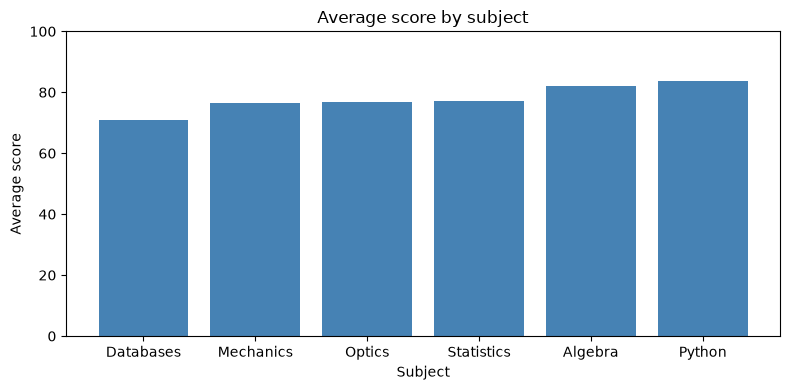

In [2]:
subject_avg = students.groupby("subject")["score"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))              # page is 8 inches wide, 4 inches tall
ax.bar(subject_avg.index, subject_avg.values, color="steelblue")  # one bar per subject
ax.set_title("Average score by subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Average score")
ax.set_ylim(0, 100)                                 # full mark scale
fig.tight_layout()                                  # keep the labels from being cut off
plt.show()


## Part 3 — Horizontal bar chart

A horizontal bar chart is the same comparison as a bar chart. The bars grow to the right, so longer names fit more easily.

This chart answers: **how many students come from each city?** The length of a bar is the number of students. Blank cities are labeled Unknown, so those students still appear.


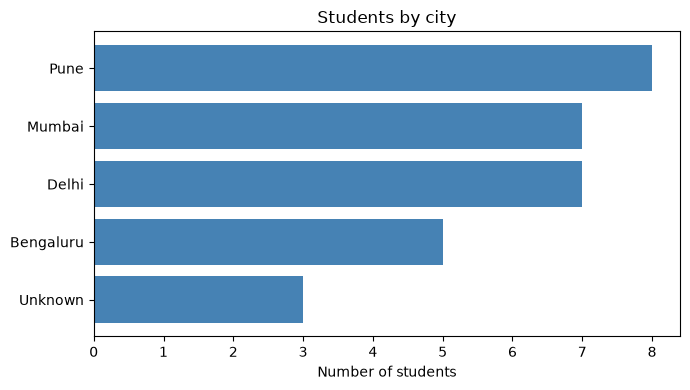

In [3]:
city_counts = students["city"].fillna("Unknown").value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(city_counts.index, city_counts.values, color="steelblue")  # length = student count
ax.invert_yaxis()                                    # longest bar at the top
ax.set_title("Students by city")
ax.set_xlabel("Number of students")
fig.tight_layout()
plt.show()


## Part 4 — Line chart

A line chart is for a number that changes along an order, usually time. The line connects the points from left to right.

This chart answers: **how does the average score change across join years?** Each dot is one year. The line between the dots is the change from that year to the next. Read it left to right.


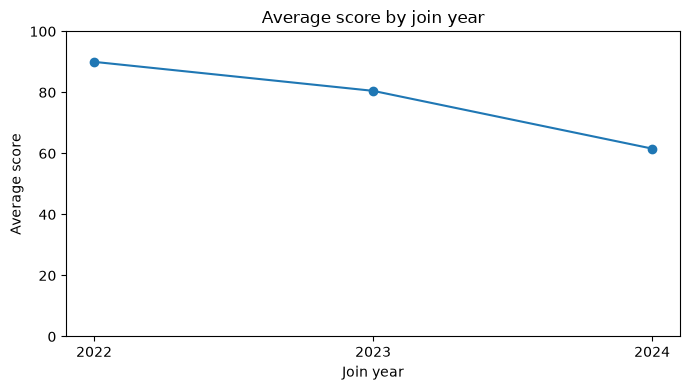

In [4]:
by_year = students.groupby(students["joined"].dt.year)["score"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by_year.index, by_year.values, marker="o")  # marker draws a dot on each year
ax.set_xticks(by_year.index)                        # label 2022, 2023, 2024 only
ax.set_title("Average score by join year")
ax.set_xlabel("Join year")
ax.set_ylabel("Average score")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()


## Part 5 — Histogram

A histogram shows how a number is spread. It groups the scores into ranges, and the height of each bar is how many students fell in that range.

This chart answers: **are most scores high, low, or spread across the scale?** These bins are 10 marks wide: 50–60, 60–70, and so on up to 100.


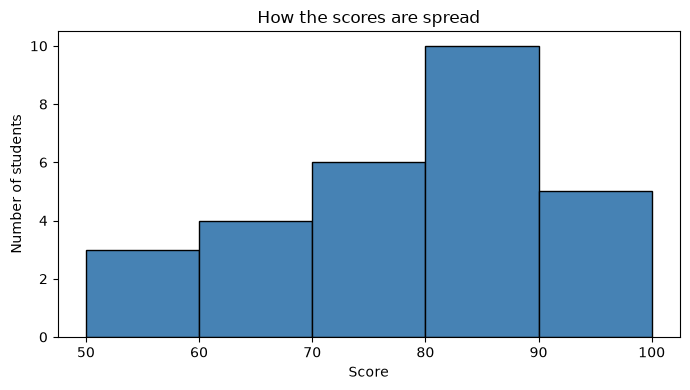

In [5]:
scores = students["score"].dropna()                 # leave out the two missing scores

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores, bins=[50, 60, 70, 80, 90, 100], edgecolor="black", color="steelblue")
ax.set_title("How the scores are spread")
ax.set_xlabel("Score")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()


## Part 6 — Scatter plot

A scatter plot puts one dot per row so you can see two numbers together.

This chart answers: **do students with higher attendance also have higher scores?** Horizontal position is attendance. Vertical position is score. Color is the department. A cloud that rises to the right means the two numbers move together.


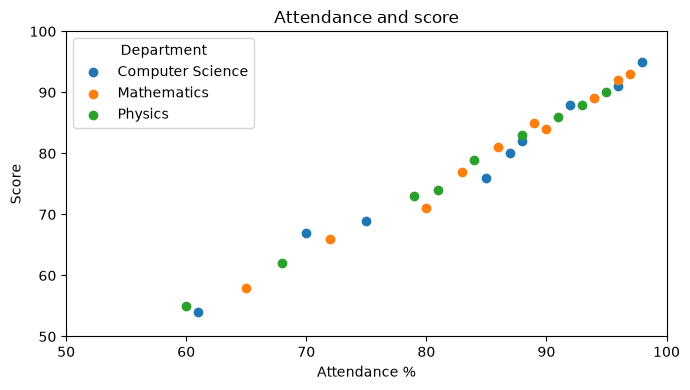

In [6]:
scored = students.dropna(subset=["score"])
departments = ["Computer Science", "Mathematics", "Physics"]

fig, ax = plt.subplots(figsize=(7, 4))
for dept in departments:
    rows = scored[scored["department"] == dept]
    ax.scatter(rows["attendance"], rows["score"], label=dept)  # one dot per student

ax.set_title("Attendance and score")
ax.set_xlabel("Attendance %")
ax.set_ylabel("Score")
ax.set_xlim(50, 100)                                 # zoom in: lowest attendance here is 60
ax.set_ylim(50, 100)                                 # lowest score here is 54
ax.legend(title="Department")                        # legend explains the colors
fig.tight_layout()
plt.show()


## Part 7 — Pie chart

A pie chart shows parts of one whole. The full circle is 100% of the students. Each slice is one status, and the number on the slice is that status's share.

This chart answers: **what share of the class is Active, Alumni, or On leave?**


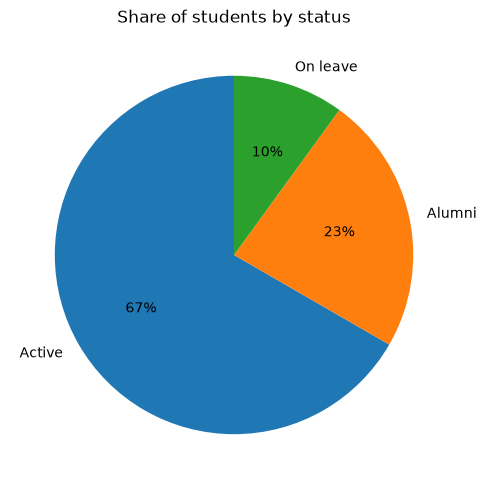

In [7]:
status_counts = students["status"].value_counts()

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.0f%%",                              # print each slice as a percent
    startangle=90,                                   # first slice starts at the top
)
ax.set_title("Share of students by status")
fig.tight_layout()
plt.show()


## Part 8 — Box plot

A box plot shows the spread of a number inside each group, which a single average hides.

Read one box like this:

- The line inside the box is the **median** (the middle score).
- The box runs from the 25% mark to the 75% mark, so it holds the middle half of the scores.
- The whiskers reach toward the lowest and highest scores.

This chart answers: **inside each department, are the scores packed together or spread out?**


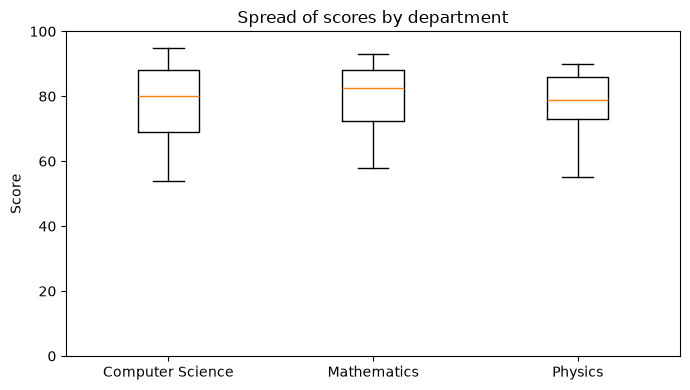

In [8]:
departments = ["Computer Science", "Mathematics", "Physics"]
groups = [
    students.loc[students["department"] == dept, "score"].dropna()
    for dept in departments
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(groups, tick_labels=departments)
ax.set_title("Spread of scores by department")
ax.set_ylabel("Score")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()


## Part 9 — Grouped bar chart

A grouped bar chart compares groups and a second category at the same time. Each cluster is one department. Inside a cluster, each color is one join year.

This chart answers: **did the drop across join years happen in every department?** Compare colors within one cluster, then move to the next department.


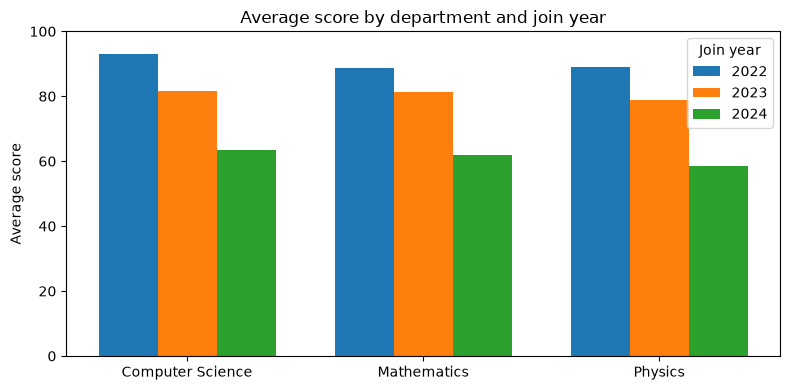

In [9]:
departments = ["Computer Science", "Mathematics", "Physics"]
years = [2022, 2023, 2024]
width = 0.25                                         # thickness of one bar
x = list(range(len(departments)))

fig, ax = plt.subplots(figsize=(8, 4))

for i, year in enumerate(years):
    heights = []
    for dept in departments:
        rows = students[
            (students["department"] == dept) & (students["joined"].dt.year == year)
        ]
        heights.append(rows["score"].mean())         # height of this department's bar
    positions = [pos + i * width for pos in x]       # shift the year sideways so bars sit side by side
    ax.bar(positions, heights, width=width, label=str(year))

ax.set_xticks([pos + width for pos in x])            # tick sits under the middle bar of each cluster
ax.set_xticklabels(departments)
ax.set_ylabel("Average score")
ax.set_ylim(0, 100)
ax.set_title("Average score by department and join year")
ax.legend(title="Join year")
fig.tight_layout()
plt.show()


## Part 10 — Two charts on one page

`plt.subplots(1, 2)` makes one page with two chart areas, side by side. `axes[0]` is the left chart. `axes[1]` is the right chart. The drawing calls are the same ones from the histogram and the scatter plot.

Putting them together lets you say two things at once: the scores pile up at the high end, and higher attendance sits with higher scores.


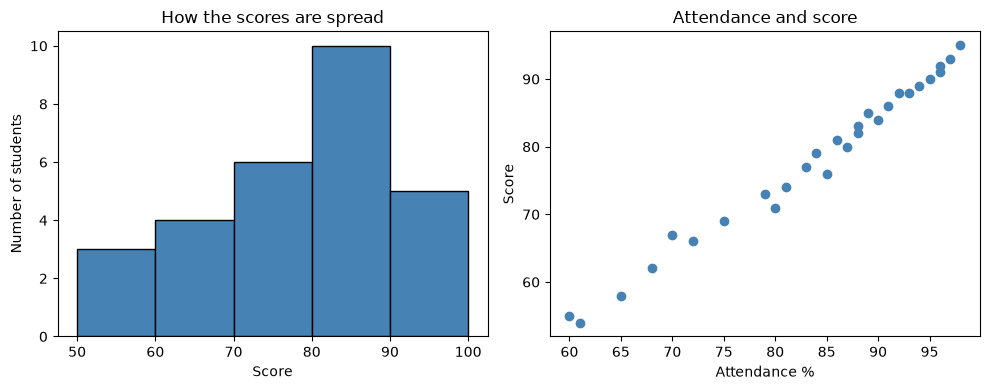

In [10]:
scored = students.dropna(subset=["score"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))     # 1 row, 2 charts

axes[0].hist(scored["score"], bins=[50, 60, 70, 80, 90, 100], edgecolor="black", color="steelblue")
axes[0].set_title("How the scores are spread")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Number of students")

axes[1].scatter(scored["attendance"], scored["score"], color="steelblue")
axes[1].set_title("Attendance and score")
axes[1].set_xlabel("Attendance %")
axes[1].set_ylabel("Score")

fig.tight_layout()
plt.show()


## Part 11 — Save the chart

`grid` draws faint guide lines so the bar heights are easier to read. `savefig` writes the page to an image file. `dpi=150` sets the sharpness. `bbox_inches="tight"` keeps the labels inside the image.

Running this cell creates `figures/subject_scores.png`.


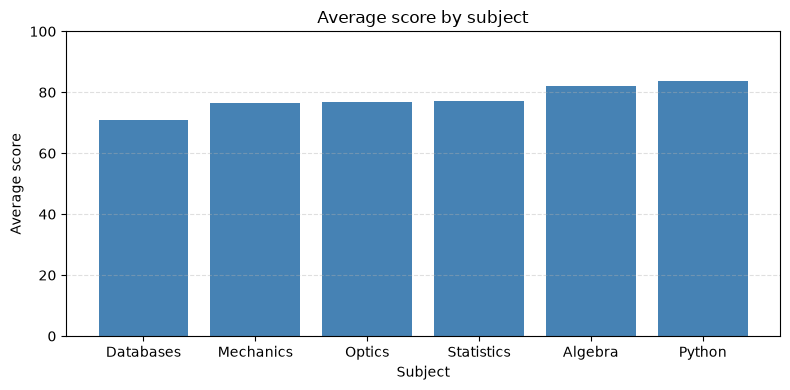

In [11]:
from pathlib import Path

subject_avg = students.groupby("subject")["score"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(subject_avg.index, subject_avg.values, color="steelblue")
ax.set_title("Average score by subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Average score")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)        # horizontal guide lines only
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/subject_scores.png", dpi=150, bbox_inches="tight")
plt.show()


## Which chart to reach for

| You want to show… | Use |
| --- | --- |
| One number for a few named groups | Bar chart, `ax.bar` |
| The same comparison when the names are long | Horizontal bar, `ax.barh` |
| Change along years or another order | Line chart, `ax.plot` |
| How a single number is spread | Histogram, `ax.hist` |
| Two numbers on each row | Scatter plot, `ax.scatter` |
| Parts of one whole | Pie chart, `ax.pie` |
| The middle and the spread inside each group | Box plot, `ax.boxplot` |
| Groups split by a second category | Grouped bars, several `ax.bar` calls shifted sideways |
| Two charts on one page | `plt.subplots(1, 2)` |
| A file you can put in slides | `fig.savefig` |
